## 1. Imports

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Dataset

In [2]:
df = pd.read_csv("customer_360_ml_workshop.csv")
df.head()

,CustomerID,Age,Region,TenureMonths,ContractType,InternetType,MonthlyUsageGB,MonthlyChargeEGP,NumServices,SupportCalls6M,LatePayments12M,PaperlessBilling,AutoPay,SatisfactionScore,Future12MRevenueEGP,Churn
0,CUST-00001,22,Alexandria,23,Month-to-month,DSL,317.9,580.48,5,5,0,Yes,Yes,5.0,6287.08,Yes
1,CUST-00002,59,Upper Egypt,9,Month-to-month,4G/5G,359.3,434.36,1,1,1,No,Yes,4.0,4619.91,No
2,CUST-00003,52,Giza,21,Month-to-month,DSL,176.9,391.35,3,5,1,Yes,Yes,5.0,4512.25,No
3,CUST-00004,41,Giza,12,Month-to-month,DSL,312.5,420.40,3,2,1,No,Yes,5.0,3809.65,No
4,CUST-00005,40,Delta,21,Month-to-month,4G/5G,191.6,462.73,3,4,0,No,Yes,3.0,4731.09,No


### 3.1 Dataset structure

In [3]:
print("Shape:", df.shape)
print()
print("Columns:")
print(list(df.columns))
print()
print("Data types:")
print(df.dtypes)
print()
df.info()

Shape: (3000, 16)

Columns:
['CustomerID', 'Age', 'Region', 'TenureMonths', 'ContractType', 'InternetType', 'MonthlyUsageGB', 'MonthlyChargeEGP', 'NumServices', 'SupportCalls6M', 'LatePayments12M', 'PaperlessBilling', 'AutoPay', 'SatisfactionScore', 'Future12MRevenueEGP', 'Churn']

Data types:
CustomerID              object
Age                      int64
Region                  object
TenureMonths             int64
ContractType            object
InternetType            object
MonthlyUsageGB         float64
MonthlyChargeEGP       float64
NumServices              int64
SupportCalls6M           int64
LatePayments12M          int64
PaperlessBilling        object
AutoPay                 object
SatisfactionScore      float64
Future12MRevenueEGP    float64
Churn                   object
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               -----------

### 3.2 Missing values

In [4]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2)
})
print("Total missing cells:", int(df.isnull().sum().sum()))
missing[missing["missing_count"] > 0]

Total missing cells: 180


,missing_count,missing_percent
InternetType,45,1.5
MonthlyUsageGB,75,2.5
SatisfactionScore,60,2.0


### 3.3 Descriptive statistics of numerical variables

In [5]:
numeric_columns = ["Age", "TenureMonths", "MonthlyUsageGB", "MonthlyChargeEGP", "NumServices",
                   "SupportCalls6M", "LatePayments12M", "SatisfactionScore", "Future12MRevenueEGP"]
df[numeric_columns].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,3000.0,44.06,15.35,18.00,31.00,44.00,57.00,70.00
TenureMonths,3000.0,25.54,16.53,1.00,13.00,22.00,35.00,72.00
MonthlyUsageGB,2925.0,230.13,89.36,10.00,169.50,228.70,290.40,597.90
MonthlyChargeEGP,3000.0,487.35,118.45,142.40,398.99,485.00,574.57,866.99
NumServices,3000.0,3.52,1.71,1.00,2.00,4.00,5.00,6.00
SupportCalls6M,3000.0,2.21,1.50,0.00,1.00,2.00,3.00,9.00
LatePayments12M,3000.0,1.11,1.07,0.00,0.00,1.00,2.00,6.00
SatisfactionScore,2940.0,3.49,1.01,1.00,3.00,4.00,4.00,5.00
Future12MRevenueEGP,3000.0,5361.16,1479.87,1529.37,4330.79,5274.62,6314.50,11095.19


### 3.4 Categorical variables

In [6]:
categorical_columns = ["Region", "ContractType", "InternetType", "PaperlessBilling", "AutoPay", "Churn"]

print("CustomerID unique values:", df["CustomerID"].nunique(), "out of", len(df))
print()

for col in categorical_columns:
    counts = df[col].value_counts(dropna=False)
    percents = (df[col].value_counts(dropna=False, normalize=True) * 100).round(2)
    print(col)
    print(pd.DataFrame({"count": counts, "percent": percents}))

CustomerID unique values: 3000 out of 3000

Region
             count  percent
Region                     
Cairo          983    32.77
Giza           597    19.90
Delta          539    17.97
Alexandria     469    15.63
Upper Egypt    412    13.73
ContractType
                count  percent
ContractType                  
Month-to-month   1680    56.00
One year          814    27.13
Two year          506    16.87
InternetType
              count  percent
InternetType                
Fiber          1350    45.00
DSL             824    27.47
4G/5G           781    26.03
NaN              45     1.50
PaperlessBilling
                  count  percent
PaperlessBilling                
Yes                2110    70.33
No                  890    29.67
AutoPay
         count  percent
AutoPay                
Yes       1684    56.13
No        1316    43.87
Churn
       count  percent
Churn                
No      2456    81.87
Yes      544    18.13


### 3.5 Churn target distribution

Count and percentage of churned vs non-churned customers.

       count  percent
Churn                
No      2456    81.87
Yes      544    18.13


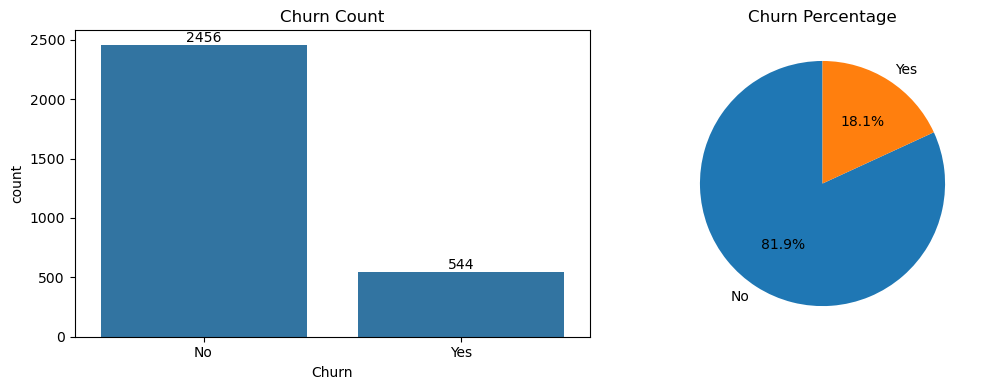

In [7]:
churn_counts = df["Churn"].value_counts()
churn_percent = (df["Churn"].value_counts(normalize=True) * 100).round(2)
churn_summary = pd.DataFrame({"count": churn_counts, "percent": churn_percent})
print(churn_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], ax=axes[0])
axes[0].set_title("Churn Count")
for container in axes[0].containers:
    axes[0].bar_label(container)
axes[1].pie(churn_counts[["No", "Yes"]], labels=["No", "Yes"], autopct="%1.1f%%", startangle=90)
axes[1].set_title("Churn Percentage")
plt.tight_layout()
plt.show()

## 4. EDA Visualizations

### 4.1 Histograms of numerical variables

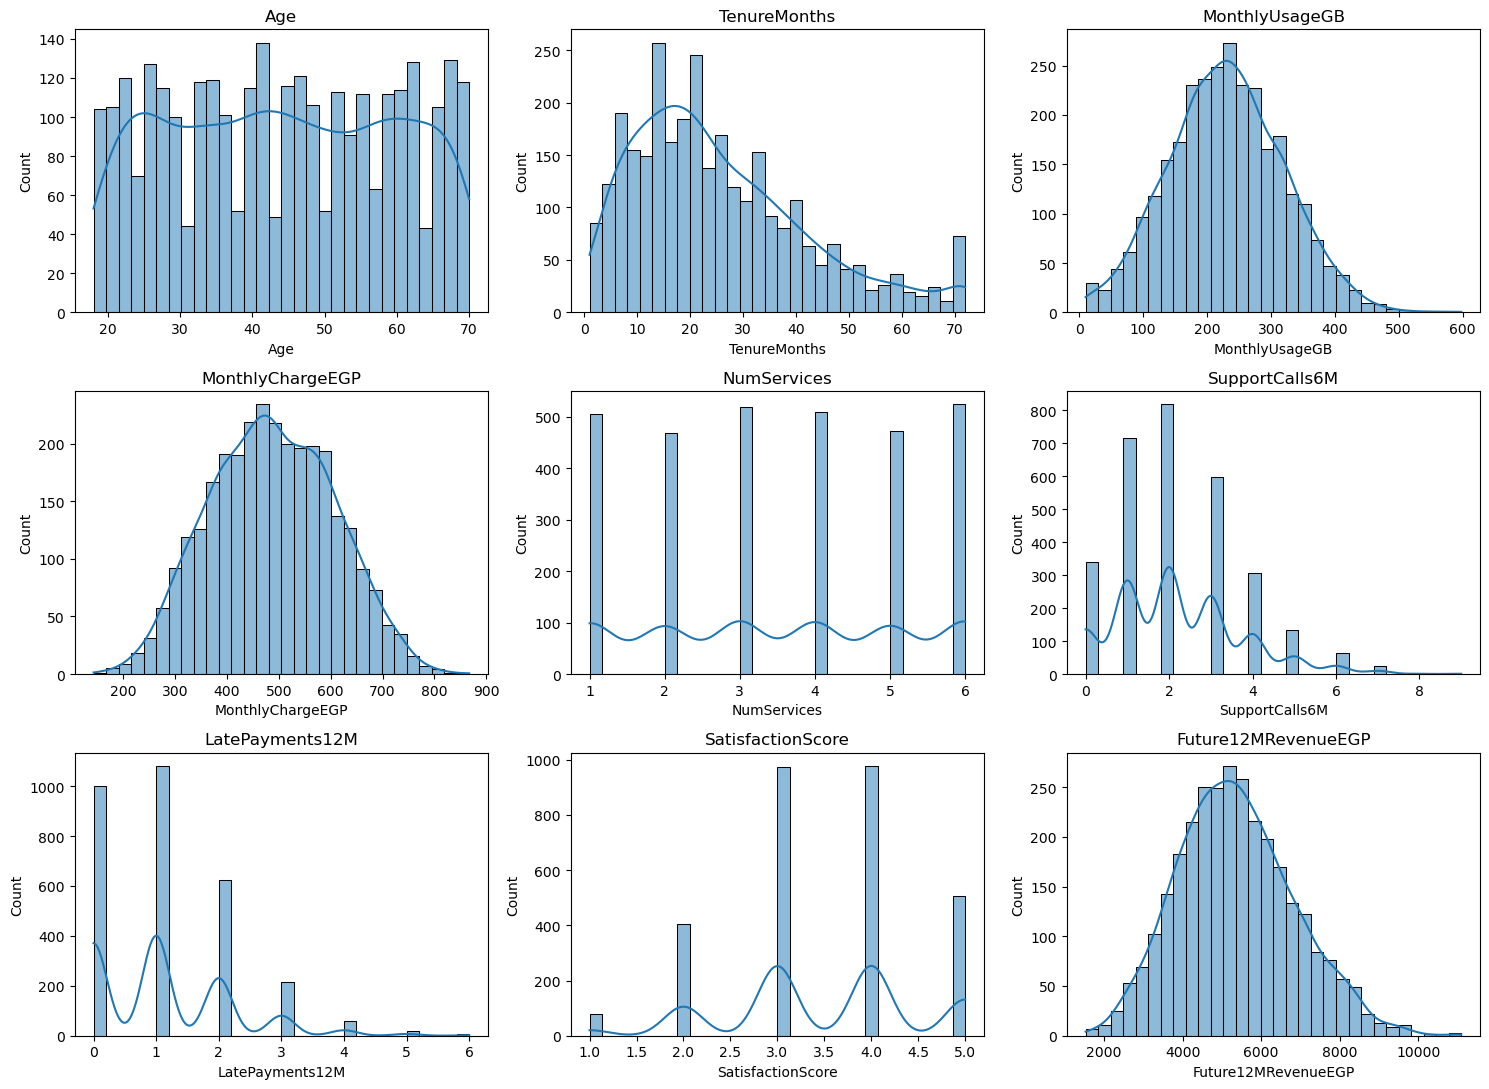

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), numeric_columns):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 4.2 Boxplots of numerical variables

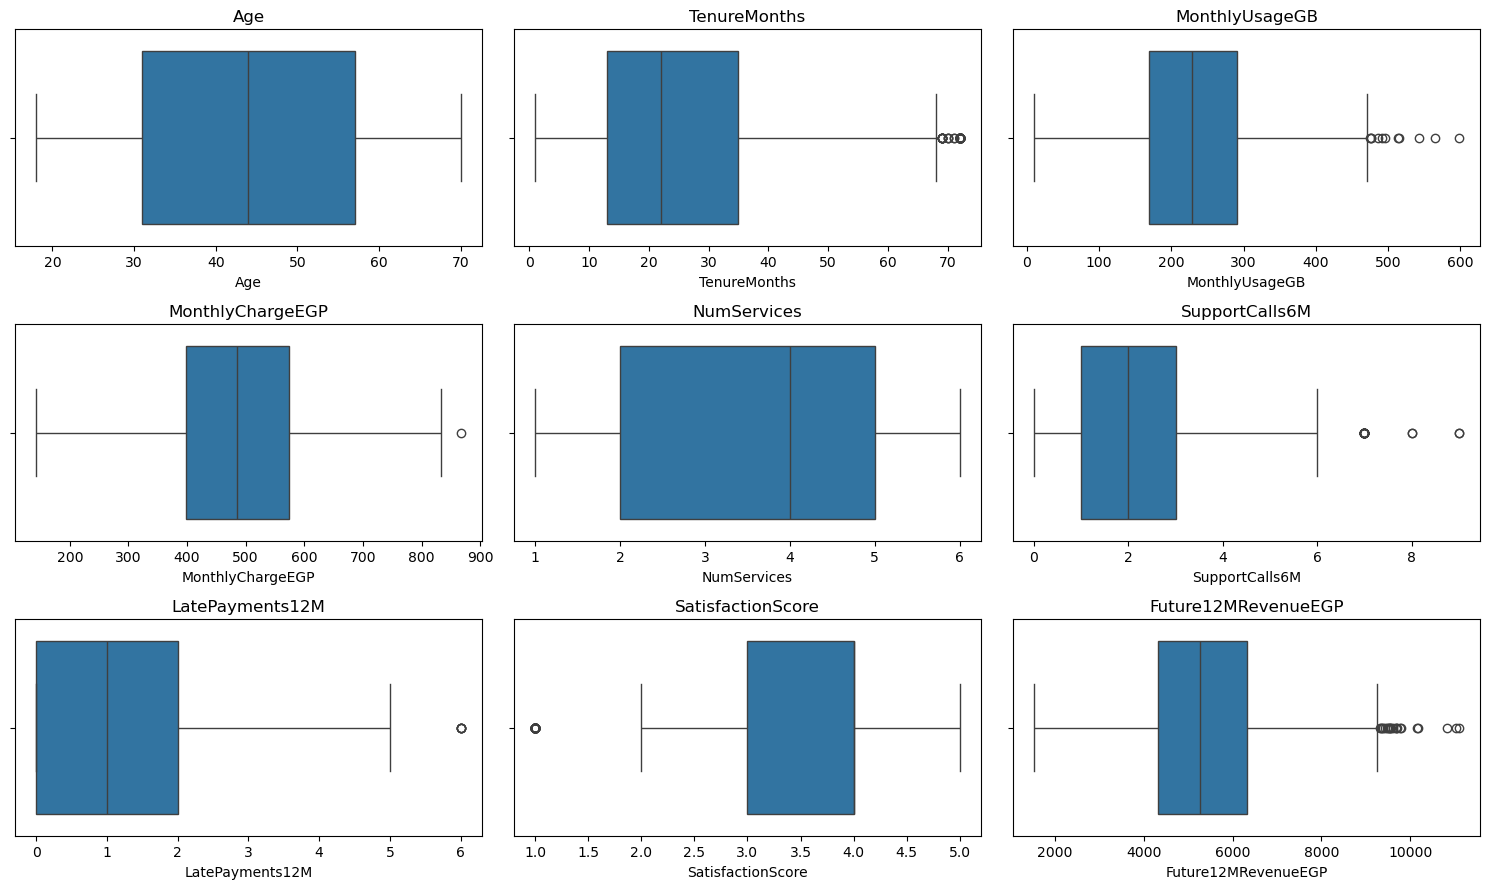

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, col in zip(axes.ravel(), numeric_columns):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 4.3 Churn by ContractType and AutoPay

Churn rate by ContractType
                customers  churn_rate_percent
ContractType                                 
Month-to-month       1680               26.61
One year              814                8.72
Two year              506                5.14

Churn rate by AutoPay
         customers  churn_rate_percent
AutoPay                               
No            1316               23.40
Yes           1684               14.01

Churn rate (%) by ContractType and AutoPay
AutoPay            No    Yes
ContractType                
Month-to-month  33.88  20.91
One year        11.76   6.35
Two year         7.24   3.51


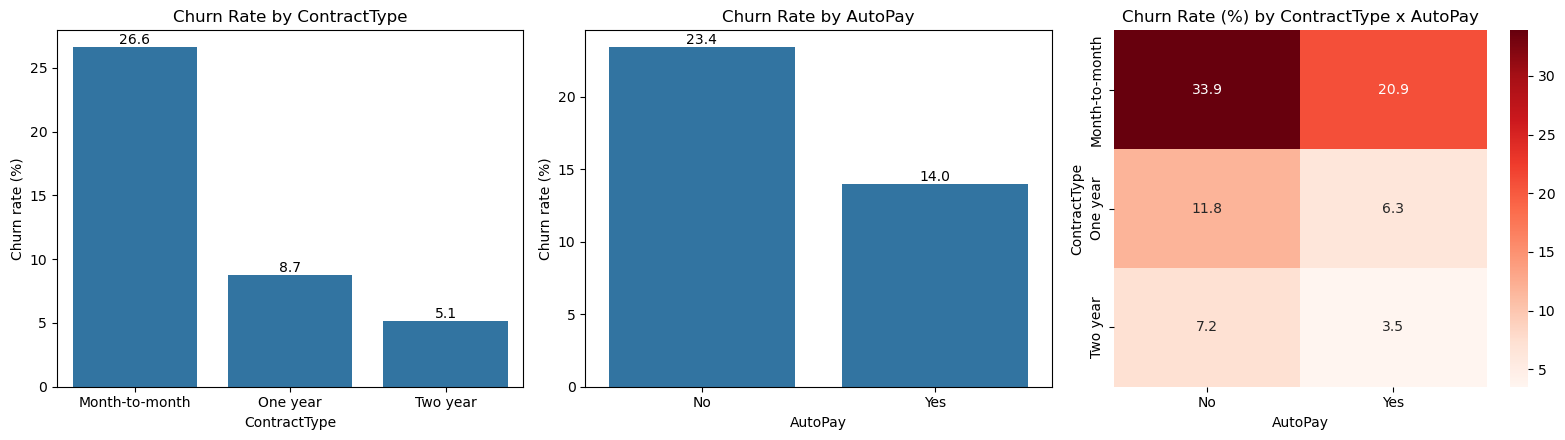

In [10]:
churn_flag = (df["Churn"] == "Yes").astype(int)

contract_summary = pd.DataFrame({
    "customers": df["ContractType"].value_counts(),
    "churn_rate_percent": (churn_flag.groupby(df["ContractType"]).mean() * 100).round(2)
})
autopay_summary = pd.DataFrame({
    "customers": df["AutoPay"].value_counts(),
    "churn_rate_percent": (churn_flag.groupby(df["AutoPay"]).mean() * 100).round(2)
})
combined_summary = (churn_flag.groupby([df["ContractType"], df["AutoPay"]]).mean() * 100).round(2).unstack()

print("Churn rate by ContractType")
print(contract_summary)
print()
print("Churn rate by AutoPay")
print(autopay_summary)
print()
print("Churn rate (%) by ContractType and AutoPay")
print(combined_summary)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(x=contract_summary.index, y=contract_summary["churn_rate_percent"], order=["Month-to-month", "One year", "Two year"], ax=axes[0])
axes[0].set_title("Churn Rate by ContractType")
axes[0].set_ylabel("Churn rate (%)")
sns.barplot(x=autopay_summary.index, y=autopay_summary["churn_rate_percent"], order=["No", "Yes"], ax=axes[1])
axes[1].set_title("Churn Rate by AutoPay")
axes[1].set_ylabel("Churn rate (%)")
sns.heatmap(combined_summary, annot=True, fmt=".1f", cmap="Reds", ax=axes[2])
axes[2].set_title("Churn Rate (%) by ContractType x AutoPay")
for ax in axes[:2]:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f")
plt.tight_layout()
plt.show()

### 4.4 Numerical variables vs Churn

Average value of each numerical variable by Churn
Churn                     No      Yes
Age                    44.11    43.83
TenureMonths           26.64    20.59
MonthlyUsageGB        230.42   228.85
MonthlyChargeEGP      485.35   496.36
NumServices             3.50     3.60
SupportCalls6M          2.15     2.44
LatePayments12M         1.07     1.29
SatisfactionScore       3.56     3.14
Future12MRevenueEGP  5428.11  5058.86


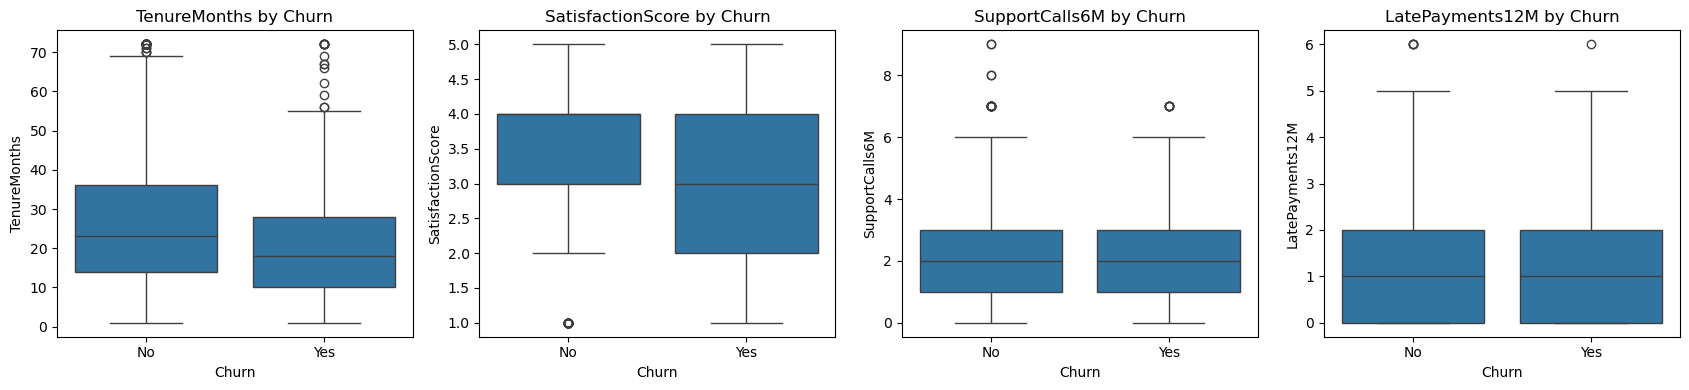

In [11]:
feature_columns = [col for col in numeric_columns if col != "Future12MRevenueEGP"]
print("Average value of each numerical variable by Churn")
print(df.groupby("Churn")[numeric_columns].mean().round(2).T)

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col in zip(axes, ["TenureMonths", "SatisfactionScore", "SupportCalls6M", "LatePayments12M"]):
    sns.boxplot(data=df, x="Churn", y=col, order=["No", "Yes"], ax=ax)
    ax.set_title(col + " by Churn")
plt.tight_layout()
plt.show()

### 4.5 Correlations and the revenue target

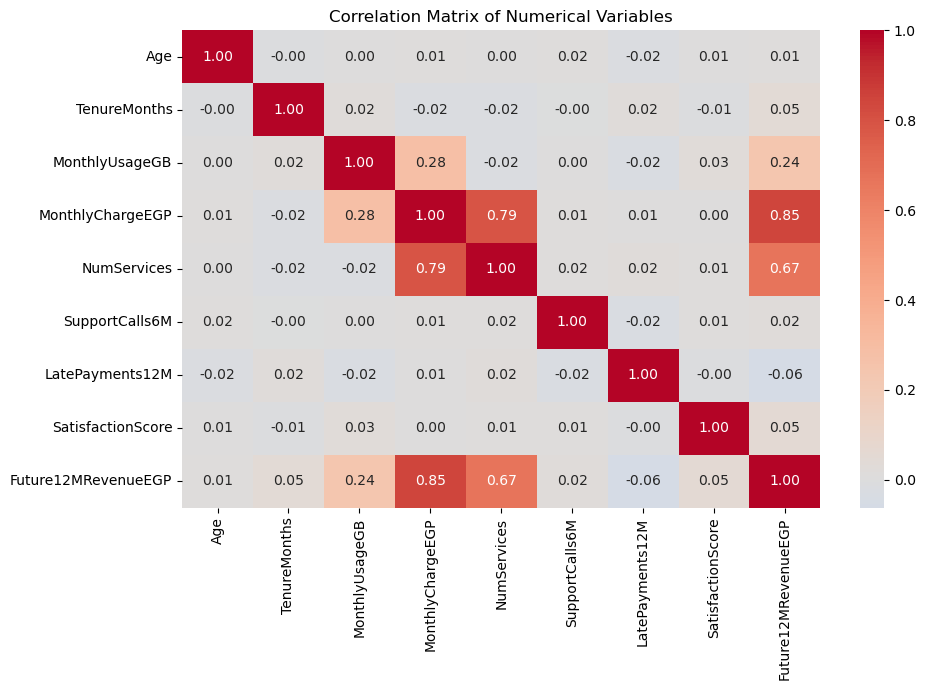

Correlation with Future12MRevenueEGP
MonthlyChargeEGP     0.850
NumServices          0.671
MonthlyUsageGB       0.244
SatisfactionScore    0.054
TenureMonths         0.047
SupportCalls6M       0.024
Age                  0.013
LatePayments12M     -0.062
Name: Future12MRevenueEGP, dtype: float64


In [12]:
correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

print("Correlation with Future12MRevenueEGP")
print(correlation_matrix["Future12MRevenueEGP"].drop("Future12MRevenueEGP").sort_values(ascending=False).round(3))

### 4.6 Main drivers of future revenue

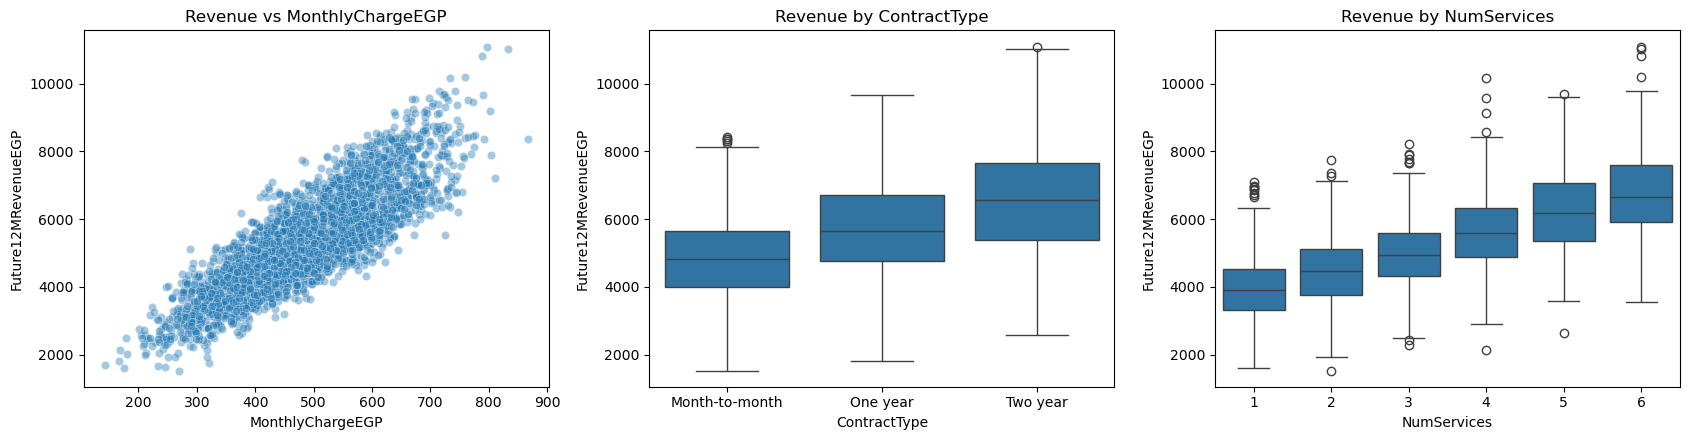

Average Future12MRevenueEGP by ContractType
ContractType
Month-to-month    4833.75
One year          5728.23
Two year          6521.71
Name: Future12MRevenueEGP, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=df, x="MonthlyChargeEGP", y="Future12MRevenueEGP", alpha=0.4, ax=axes[0])
axes[0].set_title("Revenue vs MonthlyChargeEGP")
sns.boxplot(data=df, x="ContractType", y="Future12MRevenueEGP", order=["Month-to-month", "One year", "Two year"], ax=axes[1])
axes[1].set_title("Revenue by ContractType")
sns.boxplot(data=df, x="NumServices", y="Future12MRevenueEGP", ax=axes[2])
axes[2].set_title("Revenue by NumServices")
plt.tight_layout()
plt.show()

print("Average Future12MRevenueEGP by ContractType")
print(df.groupby("ContractType")["Future12MRevenueEGP"].mean().round(2))

### 4.7 Data-quality check

In [14]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique CustomerID values:", df["CustomerID"].nunique(), "out of", len(df))
print("Non-positive Future12MRevenueEGP values:", (df["Future12MRevenueEGP"] <= 0).sum())
print("Non-positive MonthlyChargeEGP values:", (df["MonthlyChargeEGP"] <= 0).sum())
print()

quality_rows = []
for col in numeric_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    quality_rows.append({
        "Column": col,
        "Missing": df[col].isnull().sum(),
        "Skewness": round(df[col].skew(), 2),
        "IQR_Outliers": int(((df[col] < lower_limit) | (df[col] > upper_limit)).sum()),
        "Min": df[col].min(),
        "Max": df[col].max()
    })

pd.DataFrame(quality_rows)

Duplicate rows: 0
Unique CustomerID values: 3000 out of 3000
Non-positive Future12MRevenueEGP values: 0
Non-positive MonthlyChargeEGP values: 0



,Column,Missing,Skewness,IQR_Outliers,Min,Max
0,Age,0,0.01,0,18.00,70.00
1,TenureMonths,0,0.91,82,1.00,72.00
2,MonthlyUsageGB,75,0.11,11,10.00,597.90
3,MonthlyChargeEGP,0,0.04,1,142.40,866.99
4,NumServices,0,-0.01,0,1.00,6.00
5,SupportCalls6M,0,0.72,29,0.00,9.00
6,LatePayments12M,0,1.00,5,0.00,6.00
7,SatisfactionScore,60,-0.24,77,1.00,5.00
8,Future12MRevenueEGP,0,0.33,22,1529.37,11095.19


### 4.8 Column roles

Identifier, classification target, regression target and features.

In [15]:
identifier_columns = ["CustomerID"]
classification_target = "Churn"
regression_target = "Future12MRevenueEGP"

role_rows = []
for col in df.columns:
    if col in identifier_columns:
        role = "Identifier - exclude from all models"
    elif col == classification_target:
        role = "Classification target (Part C) - not a predictor for regression"
    elif col == regression_target:
        role = "Regression target (Part D) - never a predictor for churn"
    else:
        role = "Feature"
    role_rows.append({"Column": col, "Role": role})

pd.DataFrame(role_rows)

,Column,Role
0,CustomerID,Identifier - exclude from all models
1,Age,Feature
2,Region,Feature
3,TenureMonths,Feature
4,ContractType,Feature
5,InternetType,Feature
6,MonthlyUsageGB,Feature
7,MonthlyChargeEGP,Feature
8,NumServices,Feature
9,SupportCalls6M,Feature


## 5. EDA Findings

### Business observations (all numbers come from the results above)

**1. Churn is imbalanced.**
*Data:* 544 of 3,000 customers churn (18.13%) and 2,456 stay (81.87%).
*Why it matters:* a model that always predicts "No churn" would already be 81.87% accurate while finding no churners. Churn models must be judged with more than accuracy.

**2. Contract type is the strongest churn pattern.**
*Data:* churn is 26.61% for month-to-month customers, 8.72% for one-year and 5.14% for two-year contracts. Month-to-month customers are also the largest group (1,680 customers, 56%).
*Why it matters:* the biggest retention risk sits in the biggest group. Offers that move month-to-month customers to longer contracts are the most obvious retention lever.

**3. Customers without AutoPay churn more.**
*Data:* churn is 23.40% without AutoPay vs 14.01% with AutoPay. The pattern holds inside every contract type: month-to-month without AutoPay reaches 33.88%, while two-year with AutoPay is only 3.51%.
*Why it matters:* AutoPay signals commitment and removes payment friction. Encouraging AutoPay enrollment, especially for month-to-month customers, is a low-cost retention action.

**4. Churners are newer and less satisfied.**
*Data:* churners have an average tenure of 20.59 months vs 26.64 for non-churners, satisfaction of 3.14 vs 3.56, 2.44 vs 2.15 support calls and 1.29 vs 1.07 late payments. Age (43.83 vs 44.11) and monthly usage (228.85 vs 230.42 GB) are almost identical in both groups.
*Why it matters:* early-life customers, unhappy customers and customers with many support calls or late payments are the ones to monitor. Demographics and usage volume do not separate churners in this dataset.

**5. Future revenue is driven mainly by billing and contract structure.**
*Data:* the correlation with Future12MRevenueEGP is 0.850 for MonthlyChargeEGP, 0.671 for NumServices and 0.244 for MonthlyUsageGB; all other variables are below 0.07 in absolute value. Average future revenue is 4,833.75 EGP for month-to-month, 5,728.23 for one-year and 6,521.71 for two-year customers.
*Why it matters:* revenue is strongly linked to what the customer pays and how long they are committed. Cross-selling services and securing longer contracts both increase expected revenue.

**6. Churned customers have lower future revenue - which is exactly why it is leakage for churn.**
*Data:* average Future12MRevenueEGP is 5,058.86 EGP for churners vs 5,428.11 EGP for non-churners.
*Why it matters:* future revenue already reflects whether the customer stays, so it cannot be used to predict churn.

**7. Data quality is good, with light missing values and some skew.**
*Data:* 180 missing cells in only three columns (InternetType 45 = 1.50%, MonthlyUsageGB 75 = 2.50%, SatisfactionScore 60 = 2.00%). There are no duplicate rows, CustomerID is unique (3,000 of 3,000), and no revenue or charge value is zero or negative. TenureMonths (skew 0.91), LatePayments12M (1.00) and SupportCalls6M (0.72) are right-skewed, with 82, 5 and 29 IQR outliers respectively.
*Why it matters:* the missing values are small enough to impute inside the pipeline. The outliers are positive and within plausible ranges (for example tenure up to 72 months and up to 9 support calls), so they are kept as genuine customer behaviour instead of being deleted.

**8. MonthlyChargeEGP and NumServices overlap.**
*Data:* both are strongly correlated with revenue (0.850 and 0.671), and the correlation heatmap shows they are also strongly correlated with each other.
*Why it matters:* linear models can still work, but their coefficients are shared between the two variables and should not be read one by one.

### Column roles and exclusions

- **Identifier:** CustomerID - excluded from every model.
- **Classification target:** Churn (Part C, not implemented here).
- **Regression target:** Future12MRevenueEGP.
- **Excluded from the regression features:** CustomerID (identifier), Future12MRevenueEGP (it is the target) and Churn (an outcome of customer behaviour that is not a clean input for predicting future revenue and is closely tied to it - churned customers have lower revenue, as shown above).

### Answers to the Part A questions

**Q1. Which column must be excluded because it is an identifier?**
CustomerID. It is unique for all 3,000 customers, so it carries no general pattern. A model could memorize it and would fail on new customers, and it would add 3,000 meaningless one-hot columns if encoded.

**Q2. Why should Future12MRevenueEGP not be used to predict current churn?**
It describes what happens after the churn decision and is only known in the future. A customer who churns stops paying, so revenue and churn are tightly connected (5,058.86 vs 5,428.11 EGP on average). Using it would leak target information, give unrealistically good results in training and make the model useless in real life, because the value is not available when we need to predict churn.

**Q3. Is accuracy alone sufficient for churn prediction?**
No. Only 18.13% of customers churn, so predicting "No churn" for everyone gives 81.87% accuracy while missing every churner. Churn models should also be judged with recall (how many real churners are found), precision (how many flagged customers really churn), F1-score and ROC-AUC, plus the confusion matrix. Missing a churner usually costs more than contacting a customer who would have stayed.

**Q4. Which algorithms are sensitive to feature scaling?**
Algorithms based on distances or gradient/penalty terms: KNN, SVM, K-Means, PCA, neural networks, and Logistic Regression / Ridge / Lasso (regularization penalizes coefficients on different scales unequally). Tree-based models (Decision Tree, Random Forest, Gradient Boosting) are not sensitive because they split on thresholds. Plain Linear Regression gives the same predictions with or without scaling, but scaling keeps coefficients comparable.